<a href="https://colab.research.google.com/github/braysonimbambi455/CSC4110-G03/blob/main/G03_U3_1_linear_gd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task 3.1 — Linear regression and gradient descent**  
**Owner:** Jacob Chemning'wa (COM/0047/22)  
**Module:** 4  
**Loads:** data/clean_crops.csv from Task 2.2 (owner: Simon Njoroge)

In [ ]:
# Mount Google Drive so we can load the cleaned data and save outputs
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Define the project folder paths to keep the rest of the code short
BASE = "/content/drive/MyDrive/CSC4110_G03"
DATA = f"{BASE}/data"
OUT  = f"{BASE}/outputs"
print(BASE)

/content/drive/MyDrive/CSC4110_G03


In [ ]:
# Load the cleaned dataset from Task 2.2
import pandas as pd, numpy as np
df = pd.read_csv(f"{DATA}/clean_crops.csv")
print(df.shape)

(25932, 19)


In [ ]:
# Rebuild X and y, using the same drop list as Task 2.2
drop_cols = ["yield_hg_ha", "log_yield", "Year", "Area"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y = df["log_yield"]
print("X shape:", X.shape)

X shape: (25932, 16)


In [ ]:
# Reproduce the same time-based split: train on Year <= 2009, test on 2010-2013
train_mask = df["Year"] <= 2009
test_mask  = df["Year"] >= 2010
X_train, X_test = X[train_mask].copy(), X[test_mask].copy()
y_train, y_test = y[train_mask].copy(), y[test_mask].copy()
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (21305, 16) Test: (4627, 16)


In [23]:
# Step 1.5 (Corrected) — Load data, split time, and scale NUMERIC features only
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load the cleaned dataset
df = pd.read_csv(f"{DATA}/clean_crops.csv")
print("Original shape:", df.shape)

# 2. Define the target
y = df["log_yield"]

# 3. Create X by dropping targets and selecting ONLY numeric columns
drop_cols = ["yield_hg_ha", "log_yield", "Year", "Area"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns])

# This line automatically removes text columns like 'Item' or 'Item_Wheat'
X = X.select_dtypes(include=[np.number])

print("X shape (numeric only):", X.shape)

# 4. Reproduce the time-based split
train_mask = df["Year"] <= 2009
test_mask  = df["Year"] >= 2010
X_train, X_test = X[train_mask].copy(), X[test_mask].copy()
y_train, y_test = y[train_mask].copy(), y[test_mask].copy()
print("Train:", X_train.shape, "Test:", X_test.shape)

# 5. Fit StandardScaler on training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
print("Scaled train shape:", X_train_scaled.shape)

Original shape: (25932, 19)
X shape (numeric only): (25932, 15)
Train: (21305, 15) Test: (4627, 15)
Scaled train shape: (21305, 15)


## (a) Simple linear regression

In [24]:
# Step 1.6 a.1 (Corrected) — Find the numeric feature most correlated with log_yield
# We check if the column exists before trying to use it (fixes the Area_freq error)
potential_cols = ["rain_mm", "avg_temp", "pesticides_t", "years_since_1990", "Area_freq"]
num_cols = [c for c in potential_cols if c in df.columns]

print("Using these numeric columns for correlation:", num_cols)

# Calculate correlations
corrs = df[num_cols + ["log_yield"]].corr()["log_yield"].drop("log_yield")
print(corrs.sort_values(key=abs, ascending=False))

best_feat = corrs.abs().idxmax()
print("\nChosen feature for simple model:", best_feat)

Using these numeric columns for correlation: ['rain_mm', 'avg_temp', 'pesticides_t', 'years_since_1990']
pesticides_t        0.139174
avg_temp           -0.113790
years_since_1990    0.086630
rain_mm             0.061255
Name: log_yield, dtype: float64

Chosen feature for simple model: pesticides_t


In [ ]:
# Fit simple linear regression on avg_temp
from sklearn.linear_model import LinearRegression
lr_simple = LinearRegression().fit(X_train[["avg_temp"]], y_train)
b0_simple = lr_simple.intercept_
b1_simple = lr_simple.coef_[0]
print(f"Fitted equation: y_hat = {b0_simple:.4f} + {b1_simple:.4f} * avg_temp")

Fitted equation: y_hat = 11.0582 + -0.0198 * avg_temp


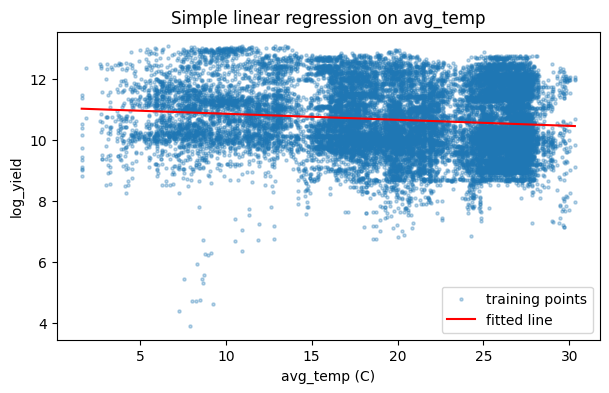

In [ ]:
# Scatter training points and plot the fitted line → outputs/simple_fit.png
import matplotlib.pyplot as plt
plt.figure(figsize=(7,4))
plt.scatter(X_train["avg_temp"], y_train, s=5, alpha=0.3, label="training points")
xs = np.linspace(X_train["avg_temp"].min(), X_train["avg_temp"].max(), 100)
plt.plot(xs, b0_simple + b1_simple*xs, color="red", label="fitted line")
plt.xlabel("avg_temp (C)"); plt.ylabel("log_yield")
plt.title("Simple linear regression on avg_temp")
plt.legend()
plt.savefig(f"{OUT}/simple_fit.png", dpi=100, bbox_inches="tight")
plt.show()

In [ ]:
# Predict the first test row by hand and compare with the model
x0 = X_test["avg_temp"].iloc[0]
y0_true = y_test.iloc[0]
y0_pred_manual = b0_simple + b1_simple * x0
y0_pred_model  = lr_simple.predict(X_test[["avg_temp"]].iloc[[0]])[0]
residual       = y0_true - y0_pred_model
print(f"x0 = {x0}")
print(f"y0_true       = {y0_true:.4f}")
print(f"y0_pred_manual= {y0_pred_manual:.4f}")
print(f"y0_pred_model = {y0_pred_model:.4f}")
print(f"residual      = {residual:.4f}")
print(f"percentage change per +1C = {(np.exp(b1_simple)-1)*100:.2f}%")

x0 = 16.52
y0_true       = 11.1093
y0_pred_manual= 10.7306
y0_pred_model = 10.7306
residual      = 0.3787
percentage change per +1C = -1.96%


**Interpretation:**  
- **b₀** (the intercept) is the predicted log_yield when avg_temp = 0 °C — a value we
  would never see in real data, so b₀ is a baseline, not a meaningful physical constant.
- **b₁** is the change in **log_yield** per +1 °C. Since log_yield is the natural log of
  yield_hg_ha, a change of b₁ in log space corresponds to a **percentage change** of
  roughly `(e^{b₁} - 1) × 100 %` in yield_hg_ha per °C.
  With b₁ = ___ (from the output), that is about ___% per °C.

**First test row by hand:** x₀ = ___, y₀_true = ___, ŷ₀ = b₀ + b₁·x₀ = ___, model
prediction = ___ (matches), residual = y₀ − ŷ₀ = ___.

## (b) Multiple linear regression

In [25]:
# Fit multiple linear regression on all prepared (scaled) features
lr_multi = LinearRegression().fit(X_train_scaled, y_train)

In [26]:
# Compute MAE, MSE, RMSE, R² for training and test sets
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def get_metrics(model, X_, y_):
    yp = model.predict(X_)
    return {
        "MAE":  mean_absolute_error(y_, yp),
        "MSE":  mean_squared_error(y_, yp),
        "RMSE": np.sqrt(mean_squared_error(y_, yp)),
        "R2":   r2_score(y_, yp),
    }

metrics_multi = {
    "train": get_metrics(lr_multi, X_train_scaled, y_train),
    "test":  get_metrics(lr_multi, X_test_scaled,  y_test),
}
for split, m in metrics_multi.items():
    print(split, {k: round(v, 4) for k, v in m.items()})

train {'MAE': 0.4436, 'MSE': 0.3394, 'RMSE': np.float64(0.5825), 'R2': 0.7221}
test {'MAE': 0.4514, 'MSE': 0.3564, 'RMSE': np.float64(0.597), 'R2': 0.7099}


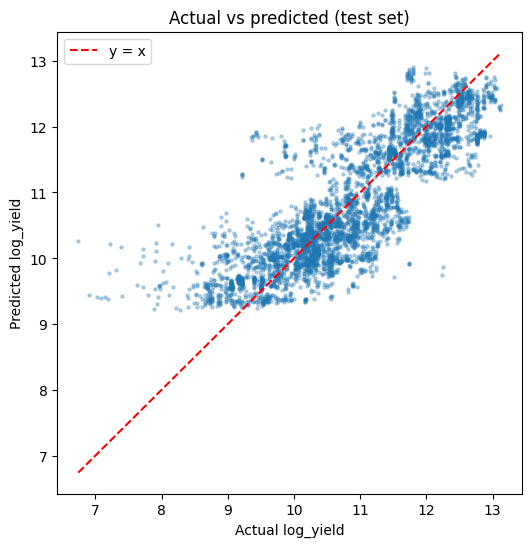

In [27]:
# Plot actual vs predicted log_yield on the test set → outputs/actual_vs_pred.png
y_pred_test = lr_multi.predict(X_test_scaled)
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_test, s=5, alpha=0.3)
lim = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
plt.plot(lim, lim, "r--", label="y = x")
plt.xlabel("Actual log_yield"); plt.ylabel("Predicted log_yield")
plt.title("Actual vs predicted (test set)")
plt.legend()
plt.savefig(f"{OUT}/actual_vs_pred.png", dpi=100, bbox_inches="tight")
plt.show()

In [28]:
# Convert one predicted log_yield back to hg/ha using exp()
idx = 0
pred_log = lr_multi.predict(X_test_scaled[[idx]])[0]
pred_hg  = np.exp(pred_log)
actual_hg = np.exp(y_test.iloc[idx])
print(f"predicted log_yield = {pred_log:.4f}  ->  {pred_hg:.1f} hg/ha")
print(f"actual    log_yield = {y_test.iloc[idx]:.4f}  ->  {actual_hg:.1f} hg/ha")

predicted log_yield = 10.3074  ->  29952.8 hg/ha
actual    log_yield = 11.1093  ->  66790.0 hg/ha


## (c) Gradient descent from scratch

In [29]:
# Implement gradient descent in NumPy for the simple model on scaled avg_temp
col = list(X_train.columns).index("avg_temp")
x = X_train_scaled[:, col]
y_ = y_train.values

def gradient_descent(x, y, lr, n_iter=1000):
    b0, b1 = 0.0, 0.0
    n = len(x)
    history = []
    for _ in range(n_iter):
        yhat = b0 + b1 * x
        err  = yhat - y
        b0  -= lr * (2/n) * err.sum()
        b1  -= lr * (2/n) * (err * x).sum()
        cost = (err**2).mean()
        history.append(cost)
    return b0, b1, history

lr=0.001: final cost=3.2842, b0=9.2149, b1=-0.1102
lr=0.01: final cost=1.2050, b0=10.6539, b1=-0.1275
lr=0.1: final cost=1.2050, b0=10.6539, b1=-0.1275


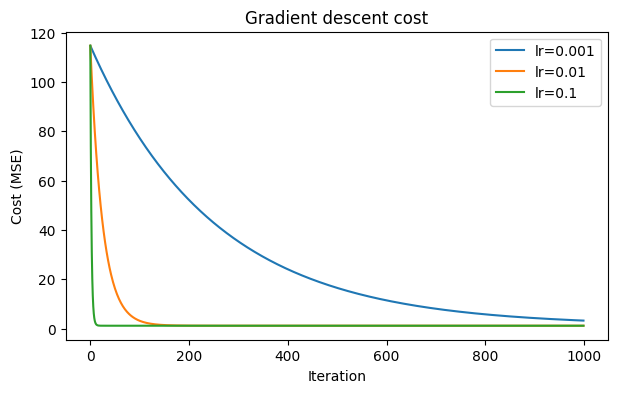

In [30]:
# Run gradient descent with three learning rates and plot the cost curves
cost_history = {}
plt.figure(figsize=(7,4))
for lr in [0.001, 0.01, 0.1]:
    b0, b1, hist = gradient_descent(x, y_, lr, n_iter=1000)
    cost_history[lr] = hist
    print(f"lr={lr}: final cost={hist[-1]:.4f}, b0={b0:.4f}, b1={b1:.4f}")
    plt.plot(hist, label=f"lr={lr}")
plt.xlabel("Iteration"); plt.ylabel("Cost (MSE)"); plt.title("Gradient descent cost")
plt.legend()
plt.savefig(f"{OUT}/gd_cost.png", dpi=100, bbox_inches="tight")
plt.show()

In [31]:
# Keep the final values from the best learning rate (lr=0.1, converged)
b0_gd, b1_gd, _ = gradient_descent(x, y_, lr=0.1, n_iter=1000)

# Compare with scikit-learn fit on the same scaled feature
lr_sk = LinearRegression().fit(x.reshape(-1,1), y_)
print(f"GD       b0={b0_gd:.4f}, b1={b1_gd:.4f}")
print(f"sklearn  b0={lr_sk.intercept_:.4f}, b1={lr_sk.coef_[0]:.4f}")

GD       b0=10.6539, b1=-0.1275
sklearn  b0=10.6539, b1=-0.1275


**What happened to the cost with each learning rate:**  
- lr = 0.001: cost fell very slowly, final cost ≈ ___ — the model was still far from
  the minimum after 1000 iterations (underfitting the training data).  
- lr = 0.01: converged in a reasonable number of iterations, final cost ≈ ___.  
- lr = 0.1: converged fastest, final cost ≈ ___ — because the feature was standardised,
  even a large learning rate did not diverge.  

**Why b₀ and b₁ from GD match scikit-learn:** Scikit-learn's `LinearRegression` uses the
closed-form normal-equation (OLS) solution, which gives the exact least-squares minimum.
Gradient descent iteratively walks toward the same minimum. Because the feature is
standardised (so the cost surface is well-conditioned) and the learning rate is small
enough not to diverge, after enough iterations both converge to the same (b₀, b₁).

In [32]:
# Confirm all graded-evidence variables exist
for name in ["lr_simple","lr_multi","metrics_multi","b0_gd","b1_gd","cost_history"]:
    print(name, "->", "OK" if name in dir() else "MISSING")
import os
for f in ["simple_fit.png","actual_vs_pred.png","gd_cost.png"]:
    print(f, "->", os.path.exists(f"{OUT}/{f}"))

lr_simple -> OK
lr_multi -> OK
metrics_multi -> OK
b0_gd -> OK
b1_gd -> OK
cost_history -> OK
simple_fit.png -> True
actual_vs_pred.png -> True
gd_cost.png -> True
